In [2]:
import sys
sys.path.append('../')
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.models.hsn_pyg import HyperScatteringModule
from hypgs.utils.data import get_hyperedge_index
import scanpy as sc
import numpy as np
import pandas as pd
import torch
from torch_geometric.utils.convert import from_networkx
from hypgs.utils.data import HGDataset
from dhg import Hypergraph
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans
from scipy.spatial import ConvexHull
from torch_geometric.data.hypergraph_data import HyperGraphData


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:47: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/libpyg.so: undefined symbol: _ZN2at4_ops12split_Tensor4callERKNS_6TensorEN3c106SymIntEl
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:90: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.con

In [3]:
adata = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad")

In [4]:
coordinates = adata.obsm['spatial']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

In [5]:
X = adata.X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /opt/conda/conda-bld/pytorch_1670525539683/work/torch/csrc/utils/tensor_new.cpp:230.)
  data[key] = torch.tensor(value)
Converting to hypergraph data: 100%|██████████| 1/1 [00:07<00:00,  7.67s/it]


In [35]:
eidf = get_hyperedge_pos_df(dataset[0], coordinates)
enlarged_hulls = compute_enlarged_hulls(eidf, )

In [7]:
# len(enlarged_hulls)

In [8]:
hulls = []
df = eidf
for set_index, group in df.groupby('he_idx'):
    points = group[['x', 'y']].values
    hull = ConvexHull(points)
    hulls.append(hull)

In [9]:
approx_radius = [np.sqrt(hull.volume/np.pi) for hull in hulls]
approx_radius = np.array(approx_radius)

In [10]:
n_cells = [hull.points.shape[0] for hull in hulls]
n_cells = np.array(n_cells)

Text(0.5, 0, 'Number of Cells')

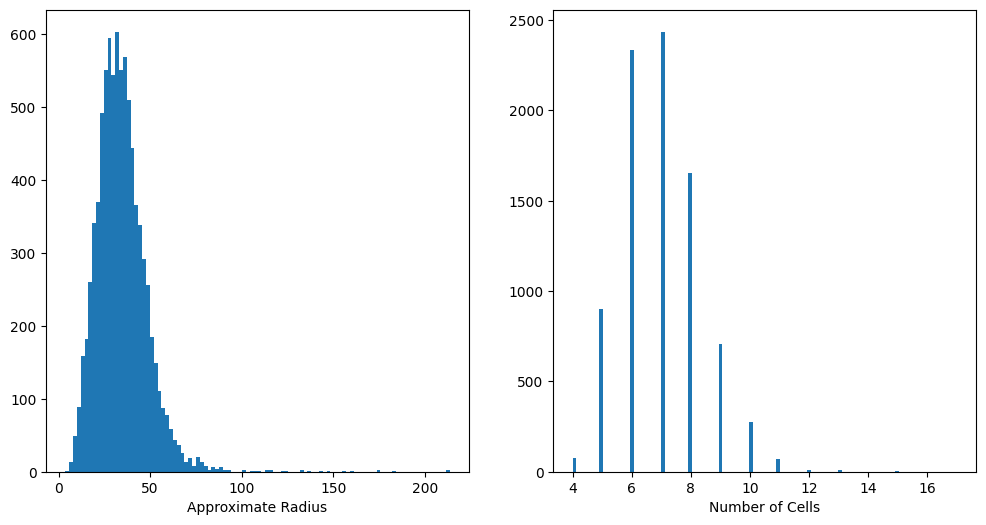

In [11]:
fig, axes = plt.subplots(1,2, figsize=(12,6))
axes[0].hist(approx_radius, 100)
axes[0].set_xlabel('Approximate Radius')
axes[1].hist(n_cells, 100)
axes[1].set_xlabel('Number of Cells')

In [12]:
model = HyperScatteringModule(in_channels=X.shape[1], 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
              reshape=False,
        )

In [13]:
s_nodes, s_edges = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)

In [14]:
shapes = s_edges.size()
he_features = s_edges.squeeze().permute(1,0,2).reshape(shapes[2], shapes[1]*shapes[3])

In [14]:
torch.save(he_features, "../data/merfish_hyperedge_GS_features.pt")

In [15]:
# eidf = get_hyperedge_pos_df(dataset[0], coordinates)
# enlarged_hulls = compute_enlarged_hulls(eidf)
# node_feats = s_nodes[0,:,:,0].detach().cpu().numpy().T
# edge_feats = s_edges[0,:,:,0].detach().cpu().numpy().T
# plot_wavelets(node_feats, edge_feats, coordinates, enlarged_hulls)

In [15]:
enc_df = pd.get_dummies(adata.obs[['Class', 'Subclass', 'Supertype']])
encoded_data = torch.tensor(enc_df.values, dtype=torch.float)

In [17]:
encoded_data.shape

torch.Size([8475, 154])

In [16]:
from torch_geometric.nn import MessagePassing

class CountCellTypesConv(MessagePassing):
    """
    Count celltypes of neighbors by message passing
    """
    def __init__(self):
        # Initialize with sum aggregation
        super(CountCellTypesConv, self).__init__(aggr='add')

    def forward(self, x, edge_index):
        return self.propagate(edge_index, x=x)

    def message(self, x_j):
        return x_j
    


In [17]:
data = HyperGraphData(edge_index=dataset[0].edge_index, x=encoded_data)
conv = CountCellTypesConv()
node_feature_counts = conv(data.x, data.edge_index)
count_df = pd.DataFrame(node_feature_counts.cpu().numpy(), columns=enc_df.columns).astype(int)
count_df.to_csv('../data/merfish_hyperedge_celltypes.csv', index=False)

In [18]:
rate_df = count_df / n_cells.reshape(-1,1)

In [19]:
rate_df.to_csv('../data/merfish_hyperedge_celltypes_rates.csv', index=False)

In [22]:
# class_cols = [col for col in count_df.columns if col.startswith('Class_')]
# rate_df[class_cols].hist()

In [23]:
# take_log = False
# nbins=10
# class_cols = [col for col in count_df.columns if col.startswith('Class_')]
# # Assuming `class_cols` is a list of marker names and `rate_df` your dataset
# n = len(class_cols) # Number of class_cols

# fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

# for i in range(n):
#     for j in range(n):
#         if i < j: # Upper off-diagonal, plot heatmap
#             node_feat_x = rate_df[class_cols[i]]
#             node_feat_y = rate_df[class_cols[j]]
#             if take_log:
#                 node_feat_x = np.log1p(node_feat_x)
#                 node_feat_y = np.log1p(node_feat_y)
#             # Calculate the density
#             x_edges = np.linspace(min(node_feat_x), max(node_feat_x), nbins)
#             y_edges = np.linspace(min(node_feat_y), max(node_feat_y), nbins)
#             density, _, _ = np.histogram2d(node_feat_x, node_feat_y, bins=[x_edges, y_edges])

#             # Plotting the heatmap
#             ax = axes[i, j]
#             ax.imshow(np.log1p(density.T), origin='lower',
#                       extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
#                       aspect='auto', cmap='viridis')
#             ax.set_xlabel(class_cols[j])
#             ax.set_ylabel(class_cols[i])

#         elif i == j: # Diagonal, plot histogram
#             node_feat = rate_df[class_cols[i]]
#             if take_log:
#                 node_feat = np.log1p(node_feat)
#             ax = axes[i, j]
#             ax.hist(node_feat, bins=nbins, color='gray')
#             ax.set_title(class_cols[i])

#         else: # Lower off-diagonal, clear the plot
#             axes[i, j].axis('off')

# plt.tight_layout()
# plt.show()


In [24]:
# top5cols = adata.obs['Subclass'].value_counts().index[:5]
# take_log = False
# nbins=10
# class_cols = ["Subclass_" + col for col in top5cols]
# # Assuming `class_cols` is a list of marker names and `rate_df` your dataset
# n = len(class_cols) # Number of class_cols

# fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

# for i in range(n):
#     for j in range(n):
#         if i < j: # Upper off-diagonal, plot heatmap
#             node_feat_x = rate_df[class_cols[i]]
#             node_feat_y = rate_df[class_cols[j]]
#             if take_log:
#                 node_feat_x = np.log1p(node_feat_x)
#                 node_feat_y = np.log1p(node_feat_y)
#             # Calculate the density
#             x_edges = np.linspace(min(node_feat_x), max(node_feat_x), nbins)
#             y_edges = np.linspace(min(node_feat_y), max(node_feat_y), nbins)
#             density, _, _ = np.histogram2d(node_feat_x, node_feat_y, bins=[x_edges, y_edges])

#             # Plotting the heatmap
#             ax = axes[i, j]
#             ax.imshow(np.log1p(density.T), origin='lower',
#                       extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
#                       aspect='auto', cmap='viridis')
#             ax.set_xlabel(class_cols[j])
#             ax.set_ylabel(class_cols[i])

#         elif i == j: # Diagonal, plot histogram
#             node_feat = rate_df[class_cols[i]]
#             if take_log:
#                 node_feat = np.log1p(node_feat)
#             ax = axes[i, j]
#             ax.hist(node_feat, bins=nbins, color='gray')
#             ax.set_title(class_cols[i])

#         else: # Lower off-diagonal, clear the plot
#             axes[i, j].axis('off')

# plt.tight_layout()
# plt.show()


In [25]:
# top5cols = adata.obs['Subclass'].value_counts().index[:5]
# take_log = False
# class_cols = ["Subclass_" + col for col in top5cols]
# # Assuming `class_cols` is a list of marker names and `count_df` your dataset
# n = len(class_cols) # Number of class_cols

# fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

# for i in range(n):
#     for j in range(n):
#         if i < j: # Upper off-diagonal, plot heatmap
#             node_feat_x = count_df[class_cols[i]]
#             node_feat_y = count_df[class_cols[j]]
#             if take_log:
#                 node_feat_x = np.log1p(node_feat_x)
#                 node_feat_y = np.log1p(node_feat_y)
#             # Calculate the density
#             x_edges = np.linspace(min(node_feat_x), max(node_feat_x))
#             y_edges = np.linspace(min(node_feat_y), max(node_feat_y))
#             density, _, _ = np.histogram2d(node_feat_x, node_feat_y)

#             # Plotting the heatmap
#             ax = axes[i, j]
#             ax.imshow(np.log1p(density.T), origin='lower',
#                       extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
#                       aspect='auto', cmap='viridis')
#             ax.set_xlabel(class_cols[j])
#             ax.set_ylabel(class_cols[i])

#         elif i == j: # Diagonal, plot histogram
#             node_feat = count_df[class_cols[i]]
#             if take_log:
#                 node_feat = np.log1p(node_feat)
#             ax = axes[i, j]
#             ax.hist(node_feat, color='gray')
#             ax.set_title(class_cols[i])

#         else: # Lower off-diagonal, clear the plot
#             axes[i, j].axis('off')

# plt.tight_layout()
# plt.show()


In [20]:
adata.obs[['Class', 'Subclass']].value_counts().sort_index()

Class                        Subclass       
Neuronal: GABAergic          Lamp5 Lhx6           94
                             Lamp5                48
                             Pax6                 11
                             Sncg                 25
                             Vip                  82
                             Sst Chodl            11
                             Sst                  74
                             Pvalb               127
                             Chandelier           16
Neuronal: Glutamatergic      L2/3 IT             526
                             L6 IT               439
                             L4 IT               426
                             L5 IT               309
                             L5 ET                51
                             L6 CT               198
                             L6b                 274
                             L6 IT Car3          543
                             L5/6 NP              54
N

In [21]:
# class_dict = {
#     'support': ['Oligodendrocyte', 'OPC', 'Astrocyte'],
#     'immune': ['Microglia-PVM'],
#     'vascular': ['Endothelial', 'VLMC'],
#     'glutamateric': ['L2/3 IT','L6 IT','L4 IT','L5 IT','L5 ET','L6 CT','L6b','L6 IT Car3','L5/6 NP'],
#     'gabaeric': ['Lamp5 Lhx6','Lamp5','Pax6','Sncg','Vip','Sst Chodl','Sst','Pvalb','Chandelier']
# }
# class_dict = {
#     'support': ['Oligodendrocyte', 'OPC', 'Astrocyte'],
#     'immune': ['Microglia-PVM'],
#     'vascular': ['Endothelial', 'VLMC'],
#     'neural': ['L2/3 IT','L6 IT','L4 IT','L5 IT','L5 ET','L6 CT','L6b','L6 IT Car3','L5/6 NP','Lamp5 Lhx6','Lamp5','Pax6','Sncg','Vip','Sst Chodl','Sst','Pvalb','Chandelier']
# }
class_dict = {
    'oligo': ['Oligodendrocyte', 'OPC'],
    'astro': ['Astrocyte'],
    'immune': ['Microglia-PVM'],
    'vascular': ['Endothelial', 'VLMC'],
    'neural': ['L2/3 IT','L6 IT','L4 IT','L5 IT',
        'L5 ET','L6 CT','L6b','L6 IT Car3','L5/6 NP',
        'Lamp5 Lhx6','Lamp5','Pax6','Sncg','Vip',
        'Sst Chodl','Sst','Pvalb','Chandelier']
}

In [22]:
# count_df[[col for col in count_df.columns if col.startswith('Subclass_')]]

In [23]:
count_coarse = pd.DataFrame(index=count_df.index)
for key, value in class_dict.items():
    value = ['Subclass_'+v for v in value]
    count_coarse[key] = count_df[value].sum(axis=1)

In [24]:
rate_coarse = count_coarse/n_cells.reshape(-1,1)

In [31]:
# from sklearn.decomposition import PCA
# pca = PCA(n_components=2)
# subclass_rates_pc = pca.fit_transform(rate_coarse)

In [32]:
# scprep.plot.scatter2d(subclass_rates_pc)

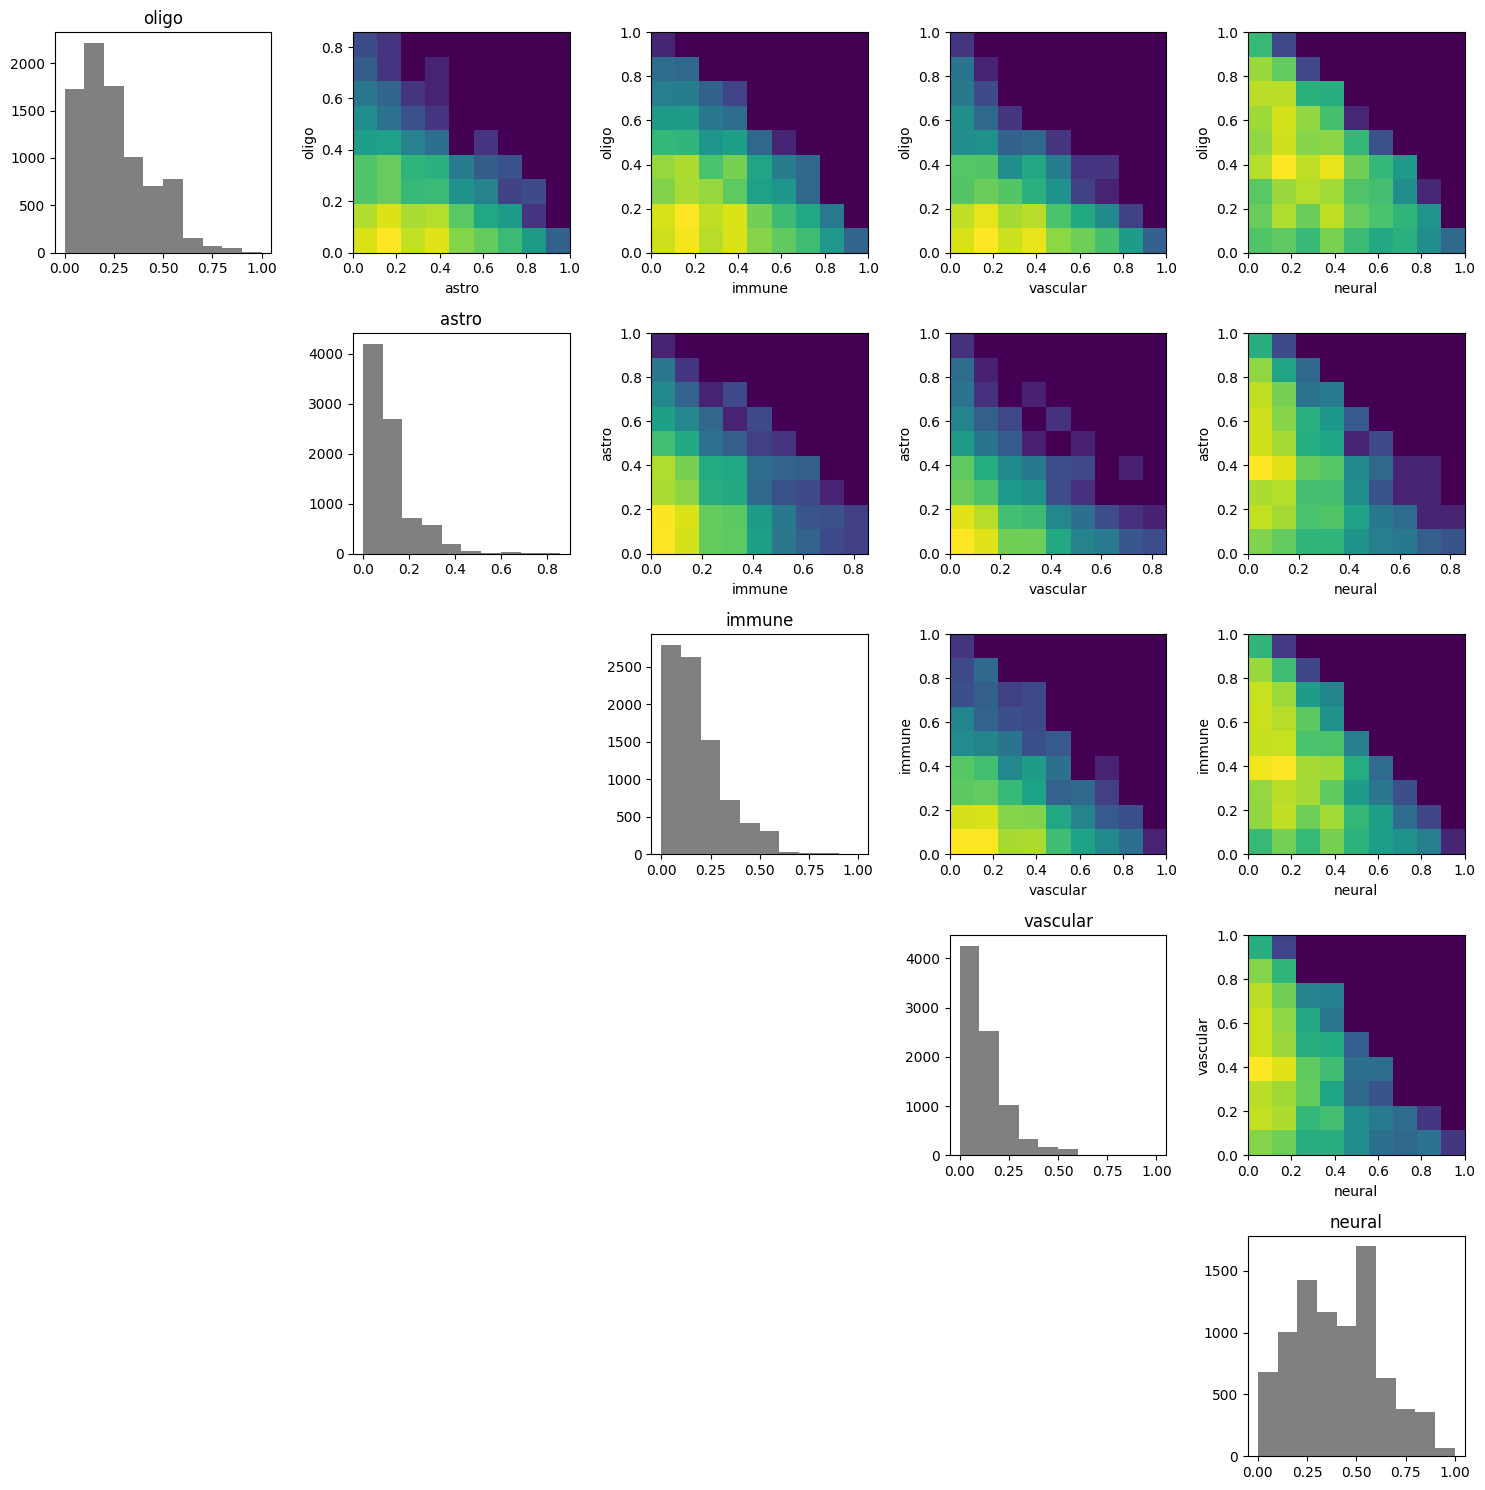

In [33]:
take_log = False
nbins=10
class_cols = count_coarse.columns.tolist()
# Assuming `class_cols` is a list of marker names and `rate_coarse` your dataset
n = len(class_cols) # Number of class_cols

fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

for i in range(n):
    for j in range(n):
        if i < j: # Upper off-diagonal, plot heatmap
            node_feat_x = rate_coarse[class_cols[i]]
            node_feat_y = rate_coarse[class_cols[j]]
            if take_log:
                node_feat_x = np.log1p(node_feat_x)
                node_feat_y = np.log1p(node_feat_y)
            # Calculate the density
            x_edges = np.linspace(min(node_feat_x), max(node_feat_x), nbins)
            y_edges = np.linspace(min(node_feat_y), max(node_feat_y), nbins)
            density, _, _ = np.histogram2d(node_feat_x, node_feat_y, bins=[x_edges, y_edges])

            # Plotting the heatmap
            ax = axes[i, j]
            ax.imshow(np.log1p(density.T), origin='lower',
                      extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
                      aspect='auto', cmap='viridis')
            ax.set_xlabel(class_cols[j])
            ax.set_ylabel(class_cols[i])

        elif i == j: # Diagonal, plot histogram
            node_feat = rate_coarse[class_cols[i]]
            if take_log:
                node_feat = np.log1p(node_feat)
            ax = axes[i, j]
            ax.hist(node_feat, bins=nbins, color='gray')
            ax.set_title(class_cols[i])

        else: # Lower off-diagonal, clear the plot
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()


In [34]:
count_coarse

,oligo,astro,immune,vascular,neural
0,1,0,1,2,2
1,2,1,2,1,4
2,1,2,2,1,3
3,1,1,1,1,4
4,3,1,1,0,2
...,...,...,...,...,...
8470,1,1,0,0,5
8471,0,0,1,2,3
8472,5,0,0,3,1
8473,1,2,1,2,0


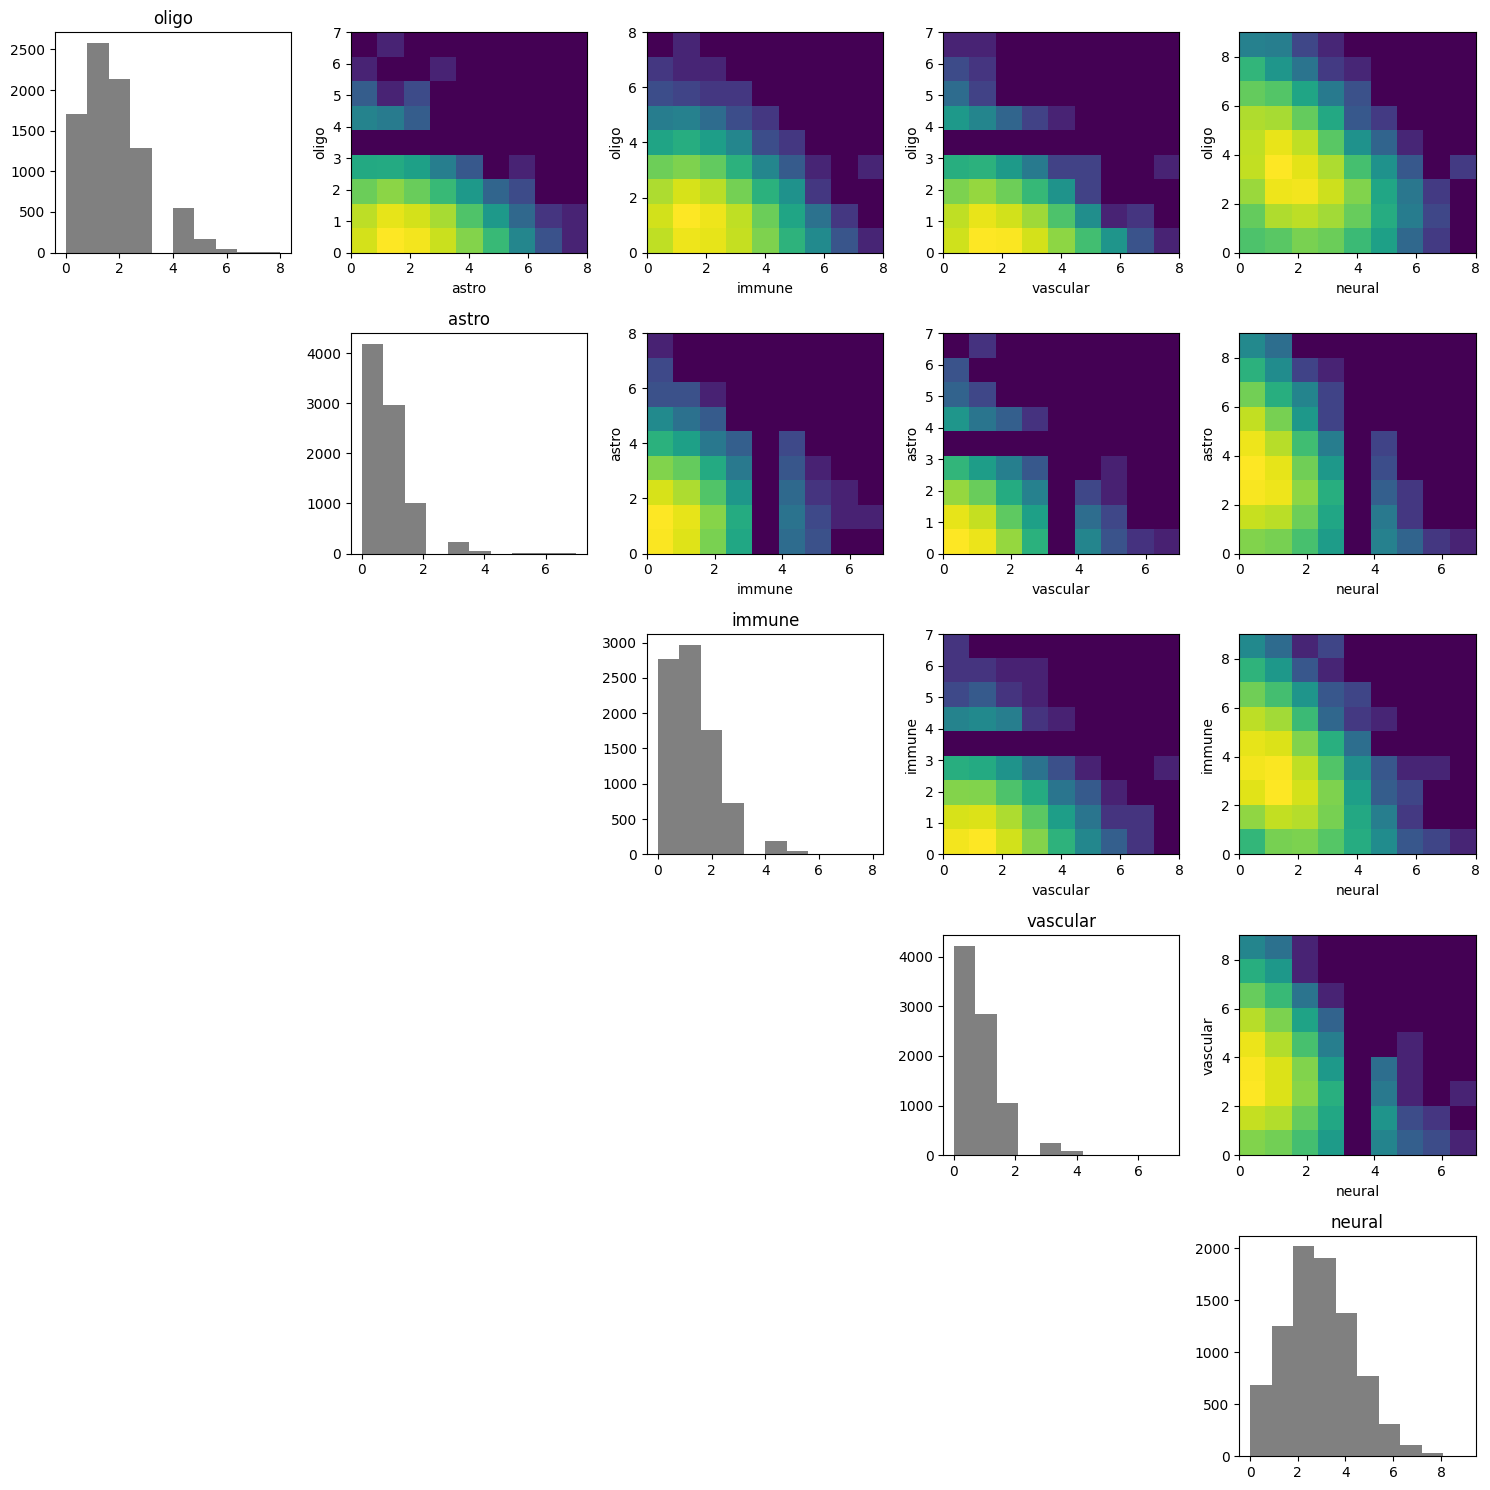

In [35]:
take_log = False
nbins=10
class_cols = count_coarse.columns.tolist()
# Assuming `class_cols` is a list of marker names and `count_coarse` your dataset
n = len(class_cols) # Number of class_cols

fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

for i in range(n):
    for j in range(n):
        if i < j: # Upper off-diagonal, plot heatmap
            node_feat_x = count_coarse[class_cols[i]]
            node_feat_y = count_coarse[class_cols[j]]
            if take_log:
                node_feat_x = np.log1p(node_feat_x)
                node_feat_y = np.log1p(node_feat_y)
            # Calculate the density
            x_edges = np.linspace(min(node_feat_x), max(node_feat_x), nbins)
            y_edges = np.linspace(min(node_feat_y), max(node_feat_y), nbins)
            density, _, _ = np.histogram2d(node_feat_x, node_feat_y, bins=[x_edges, y_edges])

            # Plotting the heatmap
            ax = axes[i, j]
            ax.imshow(np.log1p(density.T), origin='lower',
                      extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
                      aspect='auto', cmap='viridis')
            ax.set_xlabel(class_cols[j])
            ax.set_ylabel(class_cols[i])

        elif i == j: # Diagonal, plot histogram
            node_feat = count_coarse[class_cols[i]]
            if take_log:
                node_feat = np.log1p(node_feat)
            ax = axes[i, j]
            ax.hist(node_feat, bins=nbins, color='gray')
            ax.set_title(class_cols[i])

        else: # Lower off-diagonal, clear the plot
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()


In [25]:
# binarize the types into 2^5=32 types
count_coarse_bin = (count_coarse > 0).astype(int)

In [26]:
count_coarse_bin.sum(axis=1).value_counts()

3    3372
4    3115
2    1131
5     778
1      79
Name: count, dtype: int64

In [27]:
count_coarse_bin_combine = count_coarse_bin.copy()
# count_coarse_bin_combine['neural'] = count_coarse_bin_combine['glutamateric'] | count_coarse_bin_combine['gabaeric']
# count_coarse_bin_combine.drop(['glutamateric', 'gabaeric'], axis=1, inplace=True)

In [28]:
count_coarse_bin_combine

,oligo,astro,immune,vascular,neural
0,1,0,1,1,1
1,1,1,1,1,1
2,1,1,1,1,1
3,1,1,1,1,1
4,1,1,1,0,1
...,...,...,...,...,...
8470,1,1,0,0,1
8471,0,0,1,1,1
8472,1,0,0,1,1
8473,1,1,1,1,0


In [29]:
count_coarse_bin_combine['class'] = count_coarse_bin_combine.applymap(str).sum(axis=1)

In [30]:
count_coarse_bin_combine['class'].value_counts()

class
11101    1094
10101    1069
10111    1020
11111     778
11001     603
10011     593
10001     525
11011     506
00111     323
01101     320
01111     314
00101     189
11110     181
00011     152
01011     148
11100     130
10110     116
01001      91
10100      81
00001      68
01110      37
00110      34
11010      33
01100      23
11000      19
10010      10
10000       8
01010       7
00010       2
00100       1
Name: count, dtype: int64

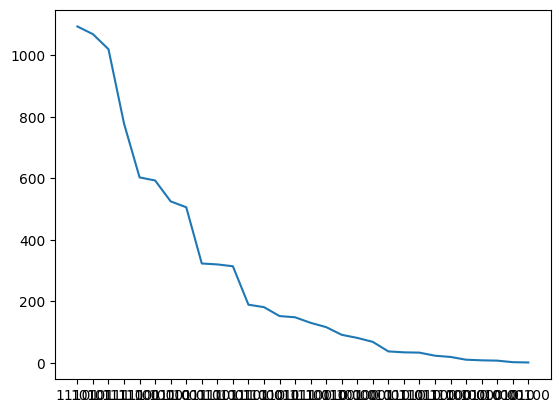

In [42]:
plt.plot(count_coarse_bin_combine['class'].value_counts())

In [43]:
np.save('../data/merfish_hyperedge_class.npy', count_coarse_bin_combine['class'].values)

In [44]:
phate_op = phate.PHATE(n_components=3)
he_phate = phate_op.fit_transform(he_features.detach().numpy())

Calculating PHATE...
  Running PHATE on 8475 observations and 1080 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...


    Calculated PCA in 0.97 seconds.
    Calculating KNN search...
    Calculated KNN search in 26.34 seconds.
    Calculating affinities...
    Calculated affinities in 1.09 seconds.
  Calculated graph and diffusion operator in 28.48 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.23 seconds.
    Calculating KMeans...
    Calculated KMeans in 21.42 seconds.
  Calculated landmark operator in 25.47 seconds.
  Calculating optimal t...
    Automatically selected t = 22
  Calculated optimal t in 11.74 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 3.90 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 75.35 seconds.
Calculated PHATE in 144.97 seconds.


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes3D: title={'center': 'Hyperedge GS coef'}>

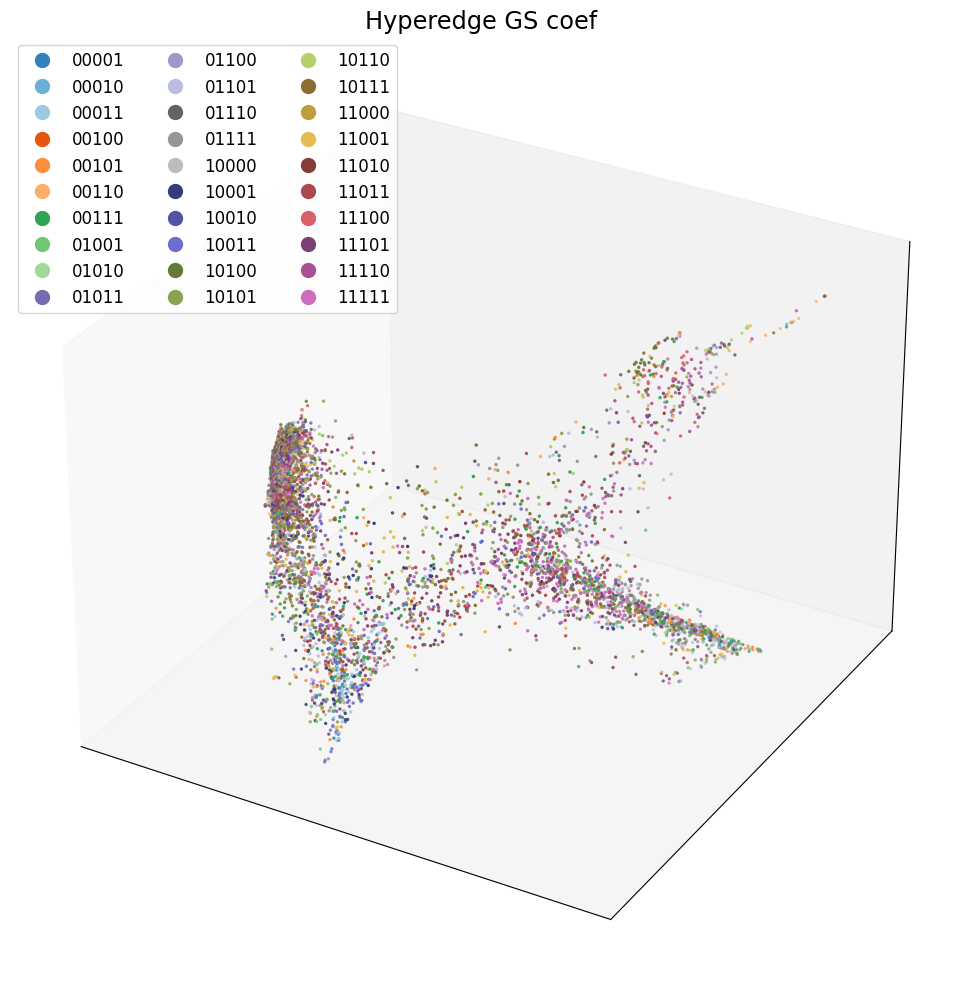

In [45]:
scprep.plot.scatter3d(he_phate, c=count_coarse_bin_combine['class'], ticks=False, figsize=(10,10), title='Hyperedge GS coef')

In [46]:
from scipy.spatial.distance import pdist, squareform, cdist
X_dist = squareform(pdist(phate_op.diff_potential))
X_dist = X_dist/X_dist.std()

In [38]:
heclass = count_coarse_bin_combine['class'].values

In [39]:
heclass_binary = count_coarse_bin_combine['class'].values

In [40]:
heclass = np.array([int(s, 2) for s in heclass_binary])

In [50]:
xor_dist = 1 - (heclass.reshape(1,-1) == heclass.reshape (-1,1))

In [51]:
triu_id = np.triu_indices(xor_dist.shape[0], k=1)
xor_dist[triu_id].mean()

0.920672374217022

In [53]:
# plt.hist(log001p_dist[triu_id], 100)
# plt.show()

In [54]:
# data_dict = dict(
#     data=he_features.detach().numpy(),
#     phate=he_phate,
#     dist=X_dist,
#     colors=heclass,
#     xor_dist=xor_dist,
#     is_train=np.ones(len(heclass)).astype(bool),
# )
# np.savez("../data/merfish_data_for_ae.npz", **data_dict)

In [55]:
pca_loadings = phate_op.graph.data_nu

In [56]:
train_mask = np.zeros(len(heclass)).astype(bool)
np.random.seed(42)
train_idx = np.random.choice(len(heclass), 3000, replace=False)
train_mask[train_idx] = True

In [57]:
data_dict = dict(
    data=pca_loadings,
    phate=he_phate,
    dist=X_dist,
    colors=heclass,
    xor_dist=xor_dist,
    is_train=train_mask,
)
np.savez("../data/merfish_data_for_ae_pca_subset.npz", **data_dict)

In [58]:
log001p_dist = squareform(pdist(np.log(rate_coarse + 0.001)))

In [59]:
data_dict = dict(
    data=pca_loadings,
    phate=he_phate,
    dist=log001p_dist,
    colors=heclass,
    xor_dist=xor_dist,
    is_train=train_mask,
)
np.savez("../data/merfish_data_for_ae_pca_log001p_dist_subset.npz", **data_dict)

In [60]:
def binary_strings_to_numpy_array(bin_strings):
    """Convert an array of binary strings to a 2D numpy array of integers."""
    return np.array([list(map(int, s)) for s in bin_strings])

def compute_pairwise_hamming(bin_strings):
    """Compute the pairwise Hamming distance matrix for an array of binary strings."""
    # Convert binary strings to a 2D numpy array
    bin_array = binary_strings_to_numpy_array(bin_strings)
    
    # Compute pairwise Hamming distances
    # Exploit broadcasting: bin_array[:, None, :] has shape (n, 1, m) and bin_array[None, :, :] has shape (1, n, m)
    # The result of the XOR operation has shape (n, n, m), and then we sum over the last dimension to count differing bits
    distance_matrix = np.sum(bin_array[:, None, :] != bin_array[None, :, :], axis=2)
    
    return distance_matrix

# Example usage
bin_strings = ["10110", "10011", "11111", "00000"]
distance_matrix = compute_pairwise_hamming(bin_strings)
print(distance_matrix)


[[0 2 2 3]
 [2 0 2 3]
 [2 2 0 5]
 [3 3 5 0]]


In [37]:
heclass

NameError: name 'heclass' is not defined

In [62]:
hamming_dist = compute_pairwise_hamming(heclass_binary)

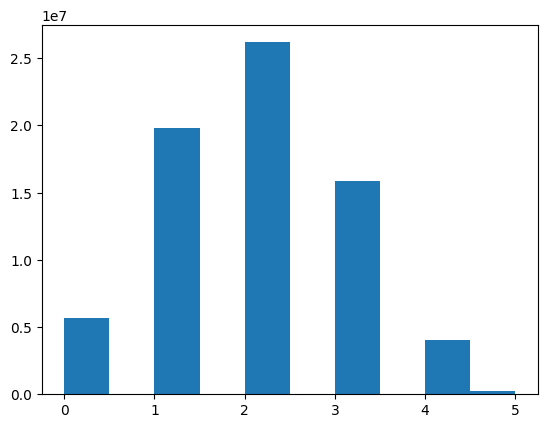

In [63]:
plt.hist(hamming_dist.flatten())
plt.show()

In [64]:
data_dict = dict(
    data=pca_loadings,
    phate=he_phate,
    dist=hamming_dist,
    colors=heclass,
    xor_dist=xor_dist,
    is_train=train_mask,
)
np.savez("../data/merfish_data_for_ae_pca_subset_hamming.npz", **data_dict)

In [65]:
xor_dist_bitwise = []
for i in range(count_coarse_bin.shape[1]):
    xor_dist_bitwise.append(1 - (count_coarse_bin.values[:,i].reshape(1,-1) == count_coarse_bin.values[:,i].reshape (-1,1)))
xor_dist_bitwise = np.array(xor_dist_bitwise)

In [66]:
xor_dist_bitwise.shape

(5, 8475, 8475)

(array([17390673., 10120282.,  7877450.,  6212328.,  6452886.,  5198376.,
         6221702.,  7461332.,  4367880.,   522716.]),
 array([0.        , 0.36579491, 0.73158982, 1.09738473, 1.46317964,
        1.82897455, 2.19476946, 2.56056437, 2.92635928, 3.29215418,
        3.65794909]),
 <BarContainer object of 10 artists>)

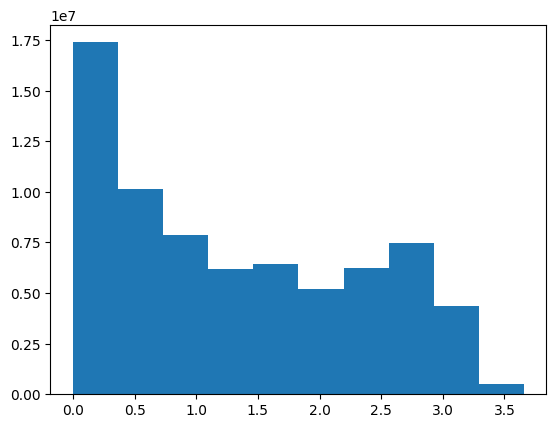

In [67]:
plt.hist(X_dist.flatten()/X_dist.std())

In [68]:
data_dict = dict(
    data=pca_loadings,
    phate=he_phate,
    dist=X_dist,
    colors=heclass,
    xor_dist=xor_dist_bitwise,
    is_train=train_mask,
)
np.savez("../data/merfish_data_for_ae_xor_bitwise_pca_subset.npz", **data_dict)

In [69]:
# data_dict = dict(
#     data=he_features.detach().numpy(),
#     phate=he_phate,
#     dist=log1p_dist,
#     colors=heclass,
#     xor_dist=xor_dist,
#     is_train=np.ones(len(heclass)).astype(bool),
# )
# np.savez("../data/merfish_data_for_ae_log1p_dist.npz", **data_dict)

In [70]:
# import numpy as np
# import matplotlib.pylab as pl
# import ot
# import ot.plot
# from ot.datasets import make_1D_gauss as gauss
# M = 1 - np.eye(4)
# x = np.arange(4, dtype=np.float32)
# a = rate_coarse.values[0,:]
# b = rate_coarse.values[1,:]
# G0 = ot.emd(a, b, M)

In [71]:
M

NameError: name 'M' is not defined

In [72]:
G0

NameError: name 'G0' is not defined

In [ ]:
enlarged_hulls = compute_enlarged_hulls(eidf, 0.1)

In [33]:
def plot_hulls(enlarged_hulls, color_values, title='', colormap=plt.cm.viridis, alpha=0.5, ax=None, show_cbar=True, transpose=False):
    if ax is None:
        fig, ax = plt.subplots()

    # Normalize color values
    norm = plt.Normalize(min(color_values), max(color_values))

    for hull, value in zip(enlarged_hulls, color_values):
        color = colormap(norm(value))
        if transpose:
            ax.fill(hull[:, 1], hull[:, 0], color=color, alpha=alpha)
        else:
            ax.fill(hull[:, 0], hull[:, 1], color=color, alpha=alpha)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    if transpose:
        ax.set_xlabel('Y Coordinate')
        ax.set_ylabel('X Coordinate')
    else:
        ax.set_xlabel('X Coordinate')
        ax.set_ylabel('Y Coordinate')
    if show_cbar:
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=colormap), ax=ax)
    # ax.show()
    ax.set_aspect('equal')
    return ax

def plot_hulls_discrete(enlarged_hulls, color_values, title='', colormap=plt.cm.tab20, alpha=0.5, ax=None, show_cbar=True, transpose=False):
    if ax is None:
        fig, ax = plt.subplots()

    # Map string labels to integers
    unique_labels = np.unique(color_values)
    label_to_int = {label: i for i, label in enumerate(unique_labels)}
    int_values = np.array([label_to_int[val] for val in color_values])

    # Use integers to index into the colormap
    cmap = colormap(np.linspace(0, 1, len(unique_labels)))

    for hull, value in zip(enlarged_hulls, int_values):
        color = cmap[value]
        if transpose:
            ax.fill(hull[:, 1], hull[:, 0], color=color, alpha=alpha)
        else:
            ax.fill(hull[:, 0], hull[:, 1], color=color, alpha=alpha)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    if transpose:
        ax.set_xlabel('Y Coordinate')
        ax.set_ylabel('X Coordinate')
    else:
        ax.set_xlabel('X Coordinate')
        ax.set_ylabel('Y Coordinate')

    if show_cbar:
        # Create a proxy artist for the colorbar
        from matplotlib.patches import Patch
        proxy_artists = [Patch(color=cmap[i], label=unique_labels[i]) for i in range(len(unique_labels))]
        plt.legend(handles=proxy_artists, bbox_to_anchor=(1.05, 1), loc='upper left')

    ax.set_aspect('equal')
    return ax


<Axes: title={'center': 'hyperedge type'}, xlabel='Y Coordinate', ylabel='X Coordinate'>

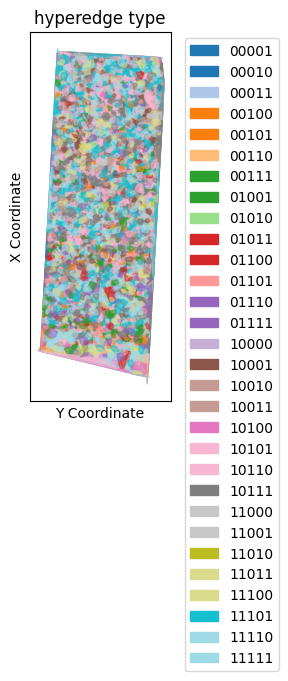

In [41]:
plot_hulls_discrete(enlarged_hulls, heclass_binary, title='hyperedge type', transpose=True)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes3D: title={'center': 'Hyperedge GS coef'}>

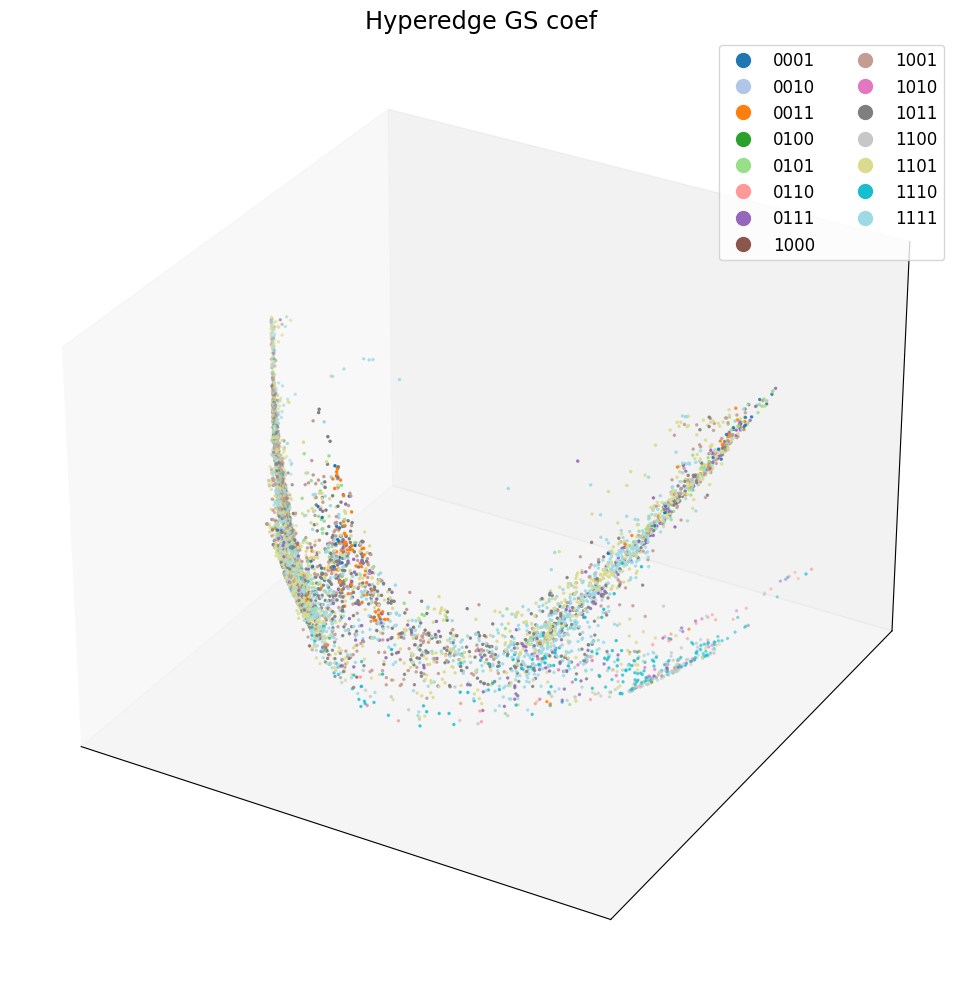

In [ ]:
scprep.plot.scatter3d(he_phate, c=heclass_binary, ticks=False, figsize=(10,10), title='Hyperedge GS coef',cmap=plt.cm.tab20)

In [ ]:
# fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# for i, ax in enumerate(axes.flatten()):
#     node_feat = s_nodes[0,i,:,0].detach().cpu().numpy()
#     scprep.plot.scatter2d(adata.obsm['spatial'], c=node_feat, ax=ax)
#     ax.set_xlabel('spatial 1')
#     ax.set_ylabel('spatial 2')
#     ax.set_xticks([])
#     ax.set_yticks([])
#     ax.set_title(f'wavelet {i}')

# plt.tight_layout()
# plt.show()


In [ ]:
triuid = np.triu_indices(len(xor_dist), 1)
xor_dist[triuid].mean()

0.8051049366342162

In [ ]:
# There are some bug in subsetting the hyperedges. need to debug later. for now we just assume the sizes are correct.
assert False

AssertionError: 

: 

In [ ]:
he_filter = (approx_radius <= 100) & (approx_radius >= 20) & (n_cells >= 5)
fig, axes = plt.subplots(1,2, figsize=(12,6))
axes[0].hist(approx_radius[he_filter], 100)
axes[0].set_xlabel('Approximate Radius')
axes[1].hist(n_cells[he_filter], 100)
axes[1].set_xlabel('Number of Cells')

: 

In [ ]:
he_filter_id = np.where(he_filter)[0]

: 

In [ ]:
he_filter_id

: 

In [ ]:
he_index_filt_id = [True if i in he_filter_id else False for i in dataset[0]['edge_index'][1].numpy()]
he_index = dataset[0]['edge_index'][:, he_index_filt_id]
he_attr = dataset[0]['edge_attr'][he_filter_id,:]


: 

In [ ]:
data = dataset[0]
mask = torch.isin(data.edge_index[1], torch.tensor(he_filter_id))
filtered_edge_index = data.edge_index[:, mask]
filtered_edge_attr = data.edge_attr[he_filter_id, :] if data.edge_attr is not None else None
node_features = data.x
edge_index = filtered_edge_index
edge_attr = filtered_edge_attr
y = data.y
new_data = HyperGraphData(x=node_features, edge_index=edge_index, edge_attr=edge_attr, y=y)

: 

In [ ]:
len(new_data['edge_index'][0].unique())

: 

In [ ]:
len(new_data['edge_index'][1].unique())

: 

In [ ]:
scprep.plot.scatter2d(adata.obsm['spatial'], c=adata.obs['Class'], s=10, alpha=0.5)

: 

In [ ]:
scprep.plot.scatter2d(adata.obsm['spatial'], c=adata.obs['Subclass'], s=50, alpha=1, figsize=(15,15))

: 

In [ ]:
model = HyperScatteringModule(in_channels=X.shape[1], 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
              reshape=False,
        )

: 

In [ ]:
s_nodes, s_edges = model(new_data.x.float(), new_data.edge_index, hyperedge_attr = new_data.edge_attr)

: 

: 